In [2]:

!pip install pymupdf pandas


In [3]:

import fitz
import pandas as pd
import os

print("Libraries imported successfully!")


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Libraries imported successfully!


In [4]:

from google.colab import files

uploaded_files = files.upload()


Saving sample_invoices_for_pdf_to_csv_project.pdf to sample_invoices_for_pdf_to_csv_project.pdf


In [5]:

pdf_file = list(uploaded_files.keys())[0]

document = fitz.open(pdf_file)

print("Total pages:", len(document))

for page_number, page in enumerate(document):
    text = page.get_text()

    print(f"\n--- Page {page_number + 1} ---")
    print(text)


Total pages: 5

--- Page 1 ---
INVOICE
SAMPLE DOCUMENT — SYNTHETIC DATA FOR LEARNING AND TESTING
Invoice ID
INV-2026-001
Invoice Date
10 November 2026
Due Date
24 November 2026
Currency
INR
Seller
Northstar Office Supplies
14 Market Road, Jaipur, Rajasthan
Bill To
ABC Learning Services
22 Station Road, Patna, Bihar
Item Details
Description
Quantity
Unit Price (INR)
Line Subtotal (INR)
Office notebooks
50
120.00
6,000.00
Subtotal
6,000.00
Tax (18%)
1,080.00
Total Amount Due
7,080.00
Note: This is a fictional sample invoice created for educational use. No real customer, company, or payment information is
included.


--- Page 2 ---
INVOICE
SAMPLE DOCUMENT — SYNTHETIC DATA FOR LEARNING AND TESTING
Invoice ID
INV-2026-002
Invoice Date
12 November 2026
Due Date
26 November 2026
Currency
INR
Seller
BluePeak Technologies
8 Tech Park, Pune, Maharashtra
Bill To
Zenith Retail Group
51 MG Road, Indore, Madhya Pradesh
Item Details
Description
Quantity
Unit Price (INR)
Line Subtotal (INR)
Wireless b

In [28]:
def extract_invoice_with_ai(page):

    invoice_text = page.get_text()

    prompt = f"""
    You are an expert invoice data extraction assistant.

    Extract these seven fields:
    Invoice_ID
    Invoice_Date
    Customer
    Product
    Quantity
    Unit_Price
    Total_Amount

    IMPORTANT INSTRUCTIONS:

    1. Extract Total_Amount from the final
       "Total Amount Due" field.

    2. Do NOT use the subtotal.

    3. Do NOT calculate Total_Amount using
       Quantity multiplied by Unit_Price.

    4. Include taxes and additional charges
       if they are included in Total Amount Due.

    5. Copy the exact final amount from the invoice.

    6. Return valid JSON only.
       Use null if a field is missing.
       Never invent information.

    INVOICE:
    {invoice_text}
    """

    messages = [
        {"role": "user", "content": prompt}
    ]

    text_input = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text_input,
        return_tensors="pt"
    ).to(model.device)

    outputs = model.generate(
        **inputs,
        max_new_tokens=300,
        do_sample=False
    )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    start = response.find("{")
    end = response.rfind("}") + 1

    if start == -1 or end == 0:
        raise ValueError("AI did not return valid JSON")

    invoice_data = json.loads(response[start:end])

    return invoice_data


print("Improved AI extraction function created!")



Improved AI extraction function created!


In [7]:
first_invoice = extract_invoice_data(document[0])

In [8]:

# Store extracted invoices
all_invoices = []

# Process every page in the PDF
for page in document:

    invoice_data = extract_invoice_data(page)

    all_invoices.append(invoice_data)

print("Total invoices extracted:", len(all_invoices))

# Display extracted records
for invoice in all_invoices:
    print(invoice)


Total invoices extracted: 5
{'Invoice_ID': 'INV-2026-001', 'Invoice_Date': '10 November 2026', 'Customer': 'ABC Learning Services', 'Product': 'Office notebooks', 'Quantity': 50, 'Unit_Price': 120.0, 'Total_Amount': 7080.0}
{'Invoice_ID': 'INV-2026-002', 'Invoice_Date': '12 November 2026', 'Customer': 'Zenith Retail Group', 'Product': 'Wireless barcode scanners', 'Quantity': 4, 'Unit_Price': 5500.0, 'Total_Amount': 25960.0}
{'Invoice_ID': 'INV-2026-003', 'Invoice_Date': '14 November 2026', 'Customer': 'PQR Food Traders', 'Product': 'Recyclable shipping boxes', 'Quantity': 120, 'Unit_Price': 45.0, 'Total_Amount': 6372.0}
{'Invoice_ID': 'INV-2026-004', 'Invoice_Date': '16 November 2026', 'Customer': 'Cedar Consulting', 'Product': 'Ergonomic office chairs', 'Quantity': 3, 'Unit_Price': 8250.0, 'Total_Amount': 29205.0}
{'Invoice_ID': 'INV-2026-005', 'Invoice_Date': '18 November 2026', 'Customer': 'Riverbend Training Centre', 'Product': 'Whiteboard marker sets', 'Quantity': 15, 'Unit_Price'

In [9]:

df = pd.DataFrame(all_invoices)

display(df)


,Invoice_ID,Invoice_Date,Customer,Product,Quantity,Unit_Price,Total_Amount
0,INV-2026-001,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,7080.0
1,INV-2026-002,12 November 2026,Zenith Retail Group,Wireless barcode scanners,4,5500.0,25960.0
2,INV-2026-003,14 November 2026,PQR Food Traders,Recyclable shipping boxes,120,45.0,6372.0
3,INV-2026-004,16 November 2026,Cedar Consulting,Ergonomic office chairs,3,8250.0,29205.0
4,INV-2026-005,18 November 2026,Riverbend Training Centre,Whiteboard marker sets,15,280.0,4956.0


In [10]:

# 1. Check dataset dimensions
print("Dataset shape:", df.shape)

# 2. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 3. Check duplicate invoice IDs
print("\nDuplicate invoice IDs:")
print(df["Invoice_ID"].duplicated().sum())

# 4. Check data types
print("\nData types:")
print(df.dtypes)

# 5. Check total invoice amount
print("\nTotal invoice amount:")
print(df["Total_Amount"].sum())


Dataset shape: (5, 7)

Missing values:
Invoice_ID      0
Invoice_Date    0
Customer        0
Product         0
Quantity        0
Unit_Price      0
Total_Amount    0
dtype: int64

Duplicate invoice IDs:
0

Data types:
Invoice_ID       object
Invoice_Date     object
Customer         object
Product          object
Quantity          int64
Unit_Price      float64
Total_Amount    float64
dtype: object

Total invoice amount:
73573.0


In [11]:

df.to_csv("extracted_invoices.csv", index=False)

print("CSV file generated successfully!")


CSV file generated successfully!


In [12]:

from google.colab import files

files.download("extracted_invoices.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

import os

# Create folder for incoming invoices
input_folder = "invoice_folder"

os.makedirs(input_folder, exist_ok=True)

print("Invoice folder created successfully!")


Invoice folder created successfully!


In [14]:

for page_number in range(len(document)):

    new_pdf = fitz.open()

    new_pdf.insert_pdf(
        document,
        from_page=page_number,
        to_page=page_number
    )

    file_name = f"invoice_{page_number + 1}.pdf"

    file_path = os.path.join(input_folder, file_name)

    new_pdf.save(file_path)

    new_pdf.close()

print("All PDF invoices separated successfully!")


All PDF invoices separated successfully!


In [15]:

import glob

# Find all PDF files
pdf_files = glob.glob(
    os.path.join(input_folder, "*.pdf")
)

print("Total PDF files found:", len(pdf_files))

for file in pdf_files:
    print(os.path.basename(file))


Total PDF files found: 5
invoice_2.pdf
invoice_1.pdf
invoice_4.pdf
invoice_5.pdf
invoice_3.pdf


In [16]:

all_invoices = []

# Process every PDF automatically
for pdf_path in pdf_files:

    pdf_document = fitz.open(pdf_path)

    for page in pdf_document:

        invoice_data = extract_invoice_data(page)

        # Track which PDF the record came from
        invoice_data["Source_File"] = os.path.basename(pdf_path)

        all_invoices.append(invoice_data)

    pdf_document.close()

print("Batch processing completed!")
print("Total invoices extracted:", len(all_invoices))


Batch processing completed!
Total invoices extracted: 5


In [17]:

batch_df = pd.DataFrame(all_invoices)

display(batch_df)


,Invoice_ID,Invoice_Date,Customer,Product,Quantity,Unit_Price,Total_Amount,Source_File
0,INV-2026-002,12 November 2026,Zenith Retail Group,Wireless barcode scanners,4,5500.0,25960.0,invoice_2.pdf
1,INV-2026-001,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,7080.0,invoice_1.pdf
2,INV-2026-004,16 November 2026,Cedar Consulting,Ergonomic office chairs,3,8250.0,29205.0,invoice_4.pdf
3,INV-2026-005,18 November 2026,Riverbend Training Centre,Whiteboard marker sets,15,280.0,4956.0,invoice_5.pdf
4,INV-2026-003,14 November 2026,PQR Food Traders,Recyclable shipping boxes,120,45.0,6372.0,invoice_3.pdf


In [18]:

batch_df.to_csv(
    "batch_extracted_invoices.csv",
    index=False
)

print("Batch CSV generated successfully!")


Batch CSV generated successfully!


In [19]:

# Dataset validation

print("Total records:", len(batch_df))

print("\nMissing values:")
print(batch_df.isnull().sum())

print("\nDuplicate invoice IDs:")
print(batch_df["Invoice_ID"].duplicated().sum())

print("\nUnique PDF files:")
print(batch_df["Source_File"].nunique())

print("\nTotal invoice amount:")
print(batch_df["Total_Amount"].sum())


Total records: 5

Missing values:
Invoice_ID      0
Invoice_Date    0
Customer        0
Product         0
Quantity        0
Unit_Price      0
Total_Amount    0
Source_File     0
dtype: int64

Duplicate invoice IDs:
0

Unique PDF files:
5

Total invoice amount:
73573.0


In [20]:

batch_df = batch_df.sort_values(
    by="Invoice_ID"
).reset_index(drop=True)

display(batch_df)


,Invoice_ID,Invoice_Date,Customer,Product,Quantity,Unit_Price,Total_Amount,Source_File
0,INV-2026-001,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,7080.0,invoice_1.pdf
1,INV-2026-002,12 November 2026,Zenith Retail Group,Wireless barcode scanners,4,5500.0,25960.0,invoice_2.pdf
2,INV-2026-003,14 November 2026,PQR Food Traders,Recyclable shipping boxes,120,45.0,6372.0,invoice_3.pdf
3,INV-2026-004,16 November 2026,Cedar Consulting,Ergonomic office chairs,3,8250.0,29205.0,invoice_4.pdf
4,INV-2026-005,18 November 2026,Riverbend Training Centre,Whiteboard marker sets,15,280.0,4956.0,invoice_5.pdf


In [21]:

batch_df.to_csv(
    "final_invoice_dataset.csv",
    index=False
)

print("Final dataset saved successfully!")


Final dataset saved successfully!


In [22]:
print("Records:", len(batch_df))
print("Missing values:", batch_df.isnull().sum().sum())
print("Duplicate IDs:", batch_df["Invoice_ID"].duplicated().sum())
print("Unique PDF files:", batch_df["Source_File"].nunique())
print("Total amount:", batch_df["Total_Amount"].sum())

Records: 5
Missing values: 0
Duplicate IDs: 0
Unique PDF files: 5
Total amount: 73573.0


In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

GPU available: True
GPU: Tesla T4


In [2]:
!pip install -q -U transformers accelerate

In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-1.5B-Instruct"

print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Loading AI model...")

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("AI model loaded successfully!")

Loading tokenizer...


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

AI model loaded successfully!


In [4]:

prompt = "Explain what an invoice is in two simple sentences."

messages = [
    {"role": "user", "content": prompt}
]

text_input = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text_input,
    return_tensors="pt"
).to(model.device)

outputs = model.generate(
    **inputs,
    max_new_tokens=100,
    do_sample=False
)

response = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("AI Response:")
print(response)


AI Response:
An invoice is a document that lists the goods or services provided and charges for them, typically used to collect payment from customers.


In [9]:
# Extract text from the first invoice
sample_text = document[0].get_text()

print(sample_text)

NameError: name 'document' is not defined

In [10]:
import fitz
from google.colab import files

uploaded_files = files.upload()

ModuleNotFoundError: No module named 'fitz'

In [11]:
!pip install -q pymupdf pandas

In [12]:
import fitz
import pandas as pd
import os

print("Libraries imported successfully!")

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Libraries imported successfully!


In [13]:
from google.colab import files

uploaded_files = files.upload()

Saving sample_invoices_for_pdf_to_csv_project.pdf to sample_invoices_for_pdf_to_csv_project.pdf


In [14]:
pdf_file = list(uploaded_files.keys())[0]

document = fitz.open(pdf_file)

print("Total pages:", len(document))

Total pages: 5


In [15]:
print("Model loaded:", "model" in globals())
print("Tokenizer loaded:", "tokenizer" in globals())

Model loaded: True
Tokenizer loaded: True


In [16]:

# Extract first invoice text
sample_text = document[0].get_text()

print(sample_text)


INVOICE
SAMPLE DOCUMENT — SYNTHETIC DATA FOR LEARNING AND TESTING
Invoice ID
INV-2026-001
Invoice Date
10 November 2026
Due Date
24 November 2026
Currency
INR
Seller
Northstar Office Supplies
14 Market Road, Jaipur, Rajasthan
Bill To
ABC Learning Services
22 Station Road, Patna, Bihar
Item Details
Description
Quantity
Unit Price (INR)
Line Subtotal (INR)
Office notebooks
50
120.00
6,000.00
Subtotal
6,000.00
Tax (18%)
1,080.00
Total Amount Due
7,080.00
Note: This is a fictional sample invoice created for educational use. No real customer, company, or payment information is
included.



In [17]:

import json

prompt = f"""
You are an invoice data extraction assistant.

Extract the following information from the invoice:

- Invoice_ID
- Invoice_Date
- Customer
- Product
- Quantity
- Unit_Price
- Total_Amount

Return valid JSON only.
Use null if information is missing.
Do not invent information.

Invoice:
{sample_text}
"""

messages = [
    {"role": "user", "content": prompt}
]

text_input = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text_input,
    return_tensors="pt"
).to(model.device)

outputs = model.generate(
    **inputs,
    max_new_tokens=300,
    do_sample=False
)

ai_response = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print(ai_response)


```json
{
  "Invoice_ID": "INV-2026-001",
  "Invoice_Date": "10 November 2026",
  "Customer": "ABC Learning Services",
  "Product": "Office notebooks",
  "Quantity": 50,
  "Unit_Price": 120.00,
  "Total_Amount": 7080.00
}
```


In [18]:

import json
import re

# Remove Markdown code fences
clean_response = re.sub(
    r"```(?:json)?",
    "",
    ai_response
).strip()

# Convert JSON text into Python dictionary
ai_invoice_data = json.loads(clean_response)

print("Extracted invoice dictionary:")
print(ai_invoice_data)

print("\nCustomer:", ai_invoice_data["Customer"])
print("Total amount:", ai_invoice_data["Total_Amount"])


Extracted invoice dictionary:
{'Invoice_ID': 'INV-2026-001', 'Invoice_Date': '10 November 2026', 'Customer': 'ABC Learning Services', 'Product': 'Office notebooks', 'Quantity': 50, 'Unit_Price': 120.0, 'Total_Amount': 7080.0}

Customer: ABC Learning Services
Total amount: 7080.0


In [19]:

# Convert AI dictionary into Pandas DataFrame

ai_df = pd.DataFrame([ai_invoice_data])

display(ai_df)


,Invoice_ID,Invoice_Date,Customer,Product,Quantity,Unit_Price,Total_Amount
0,INV-2026-001,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,7080.0


In [22]:

# Traditional Python extraction
traditional_data = extract_invoice_data(document[0])

# Compare both extraction methods
comparison = pd.DataFrame({
    "Field": list(ai_invoice_data.keys()),
    "Traditional Extraction": list(traditional_data.values()),
    "AI Extraction": list(ai_invoice_data.values())
})

display(comparison)


,Field,Traditional Extraction,AI Extraction
0,Invoice_ID,INV-2026-001,INV-2026-001
1,Invoice_Date,10 November 2026,10 November 2026
2,Customer,ABC Learning Services,ABC Learning Services
3,Product,Office notebooks,Office notebooks
4,Quantity,50,50
5,Unit_Price,120.0,120.0
6,Total_Amount,7080.0,7080.0


In [23]:
print("Total PDF pages:", len(document))

for page_number in range(len(document)):
    print(f"Page {page_number + 1}: Ready")

Total PDF pages: 5
Page 1: Ready
Page 2: Ready
Page 3: Ready
Page 4: Ready
Page 5: Ready


In [24]:

def extract_invoice_with_ai(page):

    # Extract text from PDF page
    invoice_text = page.get_text()

    prompt = f"""
    You are an invoice data extraction assistant.

    Extract these fields:
    Invoice_ID, Invoice_Date, Customer,
    Product, Quantity, Unit_Price, Total_Amount.

    Return valid JSON only.
    Use null for missing values.
    Do not invent information.

    Invoice text:
    {invoice_text}
    """

    messages = [
        {"role": "user", "content": prompt}
    ]

    text_input = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text_input,
        return_tensors="pt"
    ).to(model.device)

    outputs = model.generate(
        **inputs,
        max_new_tokens=300,
        do_sample=False
    )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    # Extract JSON from AI response
    start = response.find("{")
    end = response.rfind("}") + 1

    if start == -1 or end == 0:
        raise ValueError("AI did not return valid JSON")

    invoice_data = json.loads(response[start:end])

    return invoice_data


print("AI extraction function created successfully!")


AI extraction function created successfully!


In [25]:
test_invoice = extract_invoice_with_ai(document[0])

print(test_invoice)

{'Invoice_ID': 'INV-2026-001', 'Invoice_Date': '10 November 2026', 'Customer': 'ABC Learning Services', 'Product': 'Office notebooks', 'Quantity': 50, 'Unit_Price': 120.0, 'Total_Amount': 6000.0}


In [26]:

# Store AI-extracted invoices
all_ai_invoices = []

# Process every PDF page
for page_number, page in enumerate(document):

    print(f"Processing invoice {page_number + 1}...")

    invoice_data = extract_invoice_with_ai(page)

    all_ai_invoices.append(invoice_data)

print("\nAll invoices processed successfully!")

print("Total invoices:", len(all_ai_invoices))


Processing invoice 1...
Processing invoice 2...
Processing invoice 3...
Processing invoice 4...
Processing invoice 5...

All invoices processed successfully!
Total invoices: 5


In [27]:

# Convert AI results into a DataFrame

ai_batch_df = pd.DataFrame(all_ai_invoices)

# Display the complete dataset
display(ai_batch_df)

# Check dataset dimensions
print("Dataset shape:", ai_batch_df.shape)


,Invoice_ID,Invoice_Date,Customer,Product,Quantity,Unit_Price,Total_Amount
0,INV-2026-001,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,6000.0
1,INV-2026-002,12 November 2026,Zenith Retail Group,Wireless barcode scanners,4,5500.0,25960.0
2,INV-2026-003,14 November 2026,PQR Food Traders,Recyclable shipping boxes,120,45.0,5400.0
3,INV-2026-004,16 November 2026,Cedar Consulting,Ergonomic office chairs,3,8250.0,29205.0
4,INV-2026-005,18 November 2026,Riverbend Training Centre,Whiteboard marker sets,15,280.0,4956.0


Dataset shape: (5, 7)


In [29]:

all_ai_invoices = []

for page_number, page in enumerate(document):

    print(f"Processing invoice {page_number + 1}...")

    invoice_data = extract_invoice_with_ai(page)

    all_ai_invoices.append(invoice_data)

print("All invoices processed!")

ai_batch_df = pd.DataFrame(all_ai_invoices)

display(ai_batch_df)


Processing invoice 1...
Processing invoice 2...
Processing invoice 3...
Processing invoice 4...
Processing invoice 5...
All invoices processed!


,Invoice_ID,Invoice_Date,Customer,Product,Quantity,Unit_Price,Total_Amount
0,INV-2026-001,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,7080.0
1,INV-2026-002,12 November 2026,Zenith Retail Group,Wireless barcode scanners,4,5500.0,25960.0
2,INV-2026-003,14 November 2026,PQR Food Traders,Recyclable shipping boxes,120,45.0,6372.0
3,INV-2026-004,16 November 2026,Cedar Consulting,Ergonomic office chairs,3,8250.0,29205.0
4,INV-2026-005,18 November 2026,Riverbend Training Centre,Whiteboard marker sets,15,280.0,4956.0


In [30]:

print("Total records:", len(ai_batch_df))

print("\nMissing values:")
print(ai_batch_df.isnull().sum())

print("\nDuplicate invoice IDs:")
print(ai_batch_df["Invoice_ID"].duplicated().sum())

print("\nUnique invoice IDs:")
print(ai_batch_df["Invoice_ID"].nunique())

print("\nTotal invoice amount:")
print(ai_batch_df["Total_Amount"].sum())


Total records: 5

Missing values:
Invoice_ID      0
Invoice_Date    0
Customer        0
Product         0
Quantity        0
Unit_Price      0
Total_Amount    0
dtype: int64

Duplicate invoice IDs:
0

Unique invoice IDs:
5

Total invoice amount:
73573.0


In [31]:

# Export AI-generated dataset
ai_batch_df.to_csv(
    "AI_Extracted_Invoices.csv",
    index=False
)

print("AI invoice dataset exported successfully!")

# Download CSV
from google.colab import files

files.download("AI_Extracted_Invoices.csv")


AI invoice dataset exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:

# Compare traditional and AI extraction

traditional_df = pd.DataFrame(all_invoices)

comparison_df = traditional_df.merge(
    ai_batch_df,
    on="Invoice_ID",
    suffixes=("_Traditional", "_AI")
)

display(comparison_df)


,Invoice_ID,Invoice_Date_Traditional,Customer_Traditional,Product_Traditional,Quantity_Traditional,Unit_Price_Traditional,Total_Amount_Traditional,Invoice_Date_AI,Customer_AI,Product_AI,Quantity_AI,Unit_Price_AI,Total_Amount_AI
0,INV-2026-001,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,7080.0,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,7080.0
1,INV-2026-002,12 November 2026,Zenith Retail Group,Wireless barcode scanners,4,5500.0,25960.0,12 November 2026,Zenith Retail Group,Wireless barcode scanners,4,5500.0,25960.0
2,INV-2026-003,14 November 2026,PQR Food Traders,Recyclable shipping boxes,120,45.0,6372.0,14 November 2026,PQR Food Traders,Recyclable shipping boxes,120,45.0,6372.0
3,INV-2026-004,16 November 2026,Cedar Consulting,Ergonomic office chairs,3,8250.0,29205.0,16 November 2026,Cedar Consulting,Ergonomic office chairs,3,8250.0,29205.0
4,INV-2026-005,18 November 2026,Riverbend Training Centre,Whiteboard marker sets,15,280.0,4956.0,18 November 2026,Riverbend Training Centre,Whiteboard marker sets,15,280.0,4956.0


In [33]:

# Traditional extraction for all five invoices

all_invoices = []

for page_number, page in enumerate(document):

    print(f"Processing invoice {page_number + 1}...")

    invoice_data = extract_invoice_data(page)

    all_invoices.append(invoice_data)

print("\nTraditional extraction completed!")
print("Total invoices:", len(all_invoices))


Processing invoice 1...
Processing invoice 2...
Processing invoice 3...
Processing invoice 4...
Processing invoice 5...

Traditional extraction completed!
Total invoices: 5


In [35]:

# Compare each field between both methods

fields = [
    "Invoice_Date",
    "Customer",
    "Product",
    "Quantity",
    "Unit_Price",
    "Total_Amount"
]

for field in fields:

    traditional_col = field + "_Traditional"
    ai_col = field + "_AI"

    comparison_df[field + "_Match"] = (
        comparison_df[traditional_col].astype(str).str.strip()
        ==
        comparison_df[ai_col].astype(str).str.strip()
    )

# Display field-level comparison
match_columns = [
    "Invoice_ID"
] + [field + "_Match" for field in fields]

display(comparison_df[match_columns])


,Invoice_ID,Invoice_Date_Match,Customer_Match,Product_Match,Quantity_Match,Unit_Price_Match,Total_Amount_Match
0,INV-2026-001,True,True,True,True,True,True
1,INV-2026-002,True,True,True,True,True,True
2,INV-2026-003,True,True,True,True,True,True
3,INV-2026-004,True,True,True,True,True,True
4,INV-2026-005,True,True,True,True,True,True


In [36]:

total_checks = len(comparison_df) * len(fields)

successful_checks = sum(
    comparison_df[field + "_Match"].sum()
    for field in fields
)

accuracy = (successful_checks / total_checks) * 100

print("Total comparisons:", total_checks)
print("Successful matches:", successful_checks)
print("Mismatches:", total_checks - successful_checks)
print("Field-level match percentage:", round(accuracy, 2), "%")


Total comparisons: 30
Successful matches: 30
Mismatches: 0
Field-level match percentage: 100.0 %


In [37]:

import time

# Measure traditional extraction time
start_time = time.time()

traditional_results = []

for page in document:
    traditional_results.append(
        extract_invoice_data(page)
    )

traditional_time = time.time() - start_time

print("Traditional extraction time:",
      round(traditional_time, 2), "seconds")

# Measure AI extraction time
start_time = time.time()

ai_results = []

for page in document:
    ai_results.append(
        extract_invoice_with_ai(page)
    )

ai_time = time.time() - start_time

print("AI extraction time:",
      round(ai_time, 2), "seconds")

print("\nPerformance comparison")
print("Traditional:", round(traditional_time, 2), "seconds")
print("AI:", round(ai_time, 2), "seconds")


Traditional extraction time: 0.0 seconds
AI extraction time: 16.39 seconds

Performance comparison
Traditional: 0.0 seconds
AI: 16.39 seconds


In [38]:

import time
import pandas as pd

# Store execution times
traditional_times = []
ai_times = []

# Repeat traditional extraction 3 times
for run in range(3):

    start = time.perf_counter()

    traditional_results = [
        extract_invoice_data(page)
        for page in document
    ]

    end = time.perf_counter()

    traditional_times.append(end - start)


# Repeat AI extraction 3 times
for run in range(3):

    start = time.perf_counter()

    ai_results = [
        extract_invoice_with_ai(page)
        for page in document
    ]

    end = time.perf_counter()

    ai_times.append(end - start)


# Calculate average execution time
traditional_avg = sum(traditional_times) / len(traditional_times)
ai_avg = sum(ai_times) / len(ai_times)


# Display benchmark results
benchmark_df = pd.DataFrame({
    "Method": ["Traditional Python", "AI Extraction"],
    "Average Time (seconds)": [
        traditional_avg,
        ai_avg
    ]
})

display(benchmark_df)

print("Traditional runs:", traditional_times)
print("AI runs:", ai_times)


,Method,Average Time (seconds)
0,Traditional Python,0.003197
1,AI Extraction,17.274078


Traditional runs: [0.003769661000205815, 0.002998627000124543, 0.0028223259996593697]
AI runs: [18.26941808499987, 16.708660052999676, 16.844156615999964]


In [39]:

# Calculate speed difference

speed_ratio = ai_avg / traditional_avg

time_saved = ai_avg - traditional_avg

print("AI is approximately",
      round(speed_ratio, 2),
      "times slower than traditional Python.")

print("Time difference:",
      round(time_saved, 4),
      "seconds per five invoices.")


AI is approximately 5403.43 times slower than traditional Python.
Time difference: 17.2709 seconds per five invoices.


In [40]:

# DATA QUALITY VALIDATION

print("TRADITIONAL DATASET VALIDATION")
print("--------------------------------")

traditional_df = pd.DataFrame(all_invoices)

print("Total records:", len(traditional_df))

print("\nMissing values:")
print(traditional_df.isnull().sum())

print("\nDuplicate invoice IDs:",
      traditional_df["Invoice_ID"].duplicated().sum())

print("\nUnique invoice IDs:",
      traditional_df["Invoice_ID"].nunique())

print("\nData types:")
print(traditional_df.dtypes)


TRADITIONAL DATASET VALIDATION
--------------------------------
Total records: 5

Missing values:
Invoice_ID      0
Invoice_Date    0
Customer        0
Product         0
Quantity        0
Unit_Price      0
Total_Amount    0
dtype: int64

Duplicate invoice IDs: 0

Unique invoice IDs: 5

Data types:
Invoice_ID       object
Invoice_Date     object
Customer         object
Product          object
Quantity          int64
Unit_Price      float64
Total_Amount    float64
dtype: object


In [41]:

# AI DATASET VALIDATION

ai_validation_df = pd.DataFrame(ai_results)

print("AI DATASET VALIDATION")
print("--------------------------------")

print("Total records:", len(ai_validation_df))

print("\nMissing values:")
print(ai_validation_df.isnull().sum())

print("\nDuplicate invoice IDs:",
      ai_validation_df["Invoice_ID"].duplicated().sum())

print("\nUnique invoice IDs:",
      ai_validation_df["Invoice_ID"].nunique())

print("\nData types:")
print(ai_validation_df.dtypes)


AI DATASET VALIDATION
--------------------------------
Total records: 5

Missing values:
Invoice_ID      0
Invoice_Date    0
Customer        0
Product         0
Quantity        0
Unit_Price      0
Total_Amount    0
dtype: int64

Duplicate invoice IDs: 0

Unique invoice IDs: 5

Data types:
Invoice_ID       object
Invoice_Date     object
Customer         object
Product          object
Quantity          int64
Unit_Price      float64
Total_Amount    float64
dtype: object


In [42]:

# FINANCIAL VALIDATION

# Calculate expected amount before tax
traditional_df["Calculated_Amount"] = (
    traditional_df["Quantity"] *
    traditional_df["Unit_Price"]
)

ai_validation_df["Calculated_Amount"] = (
    ai_validation_df["Quantity"] *
    ai_validation_df["Unit_Price"]
)

# Check extracted totals against calculated amounts
traditional_df["Amount_Match"] = (
    traditional_df["Calculated_Amount"].round(2) ==
    traditional_df["Total_Amount"].round(2)
)

ai_validation_df["Amount_Match"] = (
    ai_validation_df["Calculated_Amount"].round(2) ==
    ai_validation_df["Total_Amount"].round(2)
)

print("TRADITIONAL FINANCIAL VALIDATION")
display(traditional_df[
    ["Invoice_ID", "Calculated_Amount",
     "Total_Amount", "Amount_Match"]
])

print("\nAI FINANCIAL VALIDATION")
display(ai_validation_df[
    ["Invoice_ID", "Calculated_Amount",
     "Total_Amount", "Amount_Match"]
])


TRADITIONAL FINANCIAL VALIDATION


,Invoice_ID,Calculated_Amount,Total_Amount,Amount_Match
0,INV-2026-001,6000.0,7080.0,False
1,INV-2026-002,22000.0,25960.0,False
2,INV-2026-003,5400.0,6372.0,False
3,INV-2026-004,24750.0,29205.0,False
4,INV-2026-005,4200.0,4956.0,False



AI FINANCIAL VALIDATION


,Invoice_ID,Calculated_Amount,Total_Amount,Amount_Match
0,INV-2026-001,6000.0,7080.0,False
1,INV-2026-002,22000.0,25960.0,False
2,INV-2026-003,5400.0,6372.0,False
3,INV-2026-004,24750.0,29205.0,False
4,INV-2026-005,4200.0,4956.0,False


In [43]:

# Financial validation including 18% GST

GST_RATE = 0.18

for df in [traditional_df, ai_validation_df]:

    df["Calculated_Subtotal"] = (
        df["Quantity"] * df["Unit_Price"]
    )

    df["Calculated_GST"] = (
        df["Calculated_Subtotal"] * GST_RATE
    )

    df["Expected_Total"] = (
        df["Calculated_Subtotal"] +
        df["Calculated_GST"]
    )

    df["Amount_Match"] = (
        df["Expected_Total"].round(2) ==
        df["Total_Amount"].round(2)
    )

print("TRADITIONAL VALIDATION")
display(traditional_df[
    ["Invoice_ID", "Calculated_Subtotal",
     "Calculated_GST", "Total_Amount",
     "Expected_Total", "Amount_Match"]
])

print("AI VALIDATION")
display(ai_validation_df[
    ["Invoice_ID", "Calculated_Subtotal",
     "Calculated_GST", "Total_Amount",
     "Expected_Total", "Amount_Match"]
])


TRADITIONAL VALIDATION


,Invoice_ID,Calculated_Subtotal,Calculated_GST,Total_Amount,Expected_Total,Amount_Match
0,INV-2026-001,6000.0,1080.0,7080.0,7080.0,True
1,INV-2026-002,22000.0,3960.0,25960.0,25960.0,True
2,INV-2026-003,5400.0,972.0,6372.0,6372.0,True
3,INV-2026-004,24750.0,4455.0,29205.0,29205.0,True
4,INV-2026-005,4200.0,756.0,4956.0,4956.0,True


AI VALIDATION


,Invoice_ID,Calculated_Subtotal,Calculated_GST,Total_Amount,Expected_Total,Amount_Match
0,INV-2026-001,6000.0,1080.0,7080.0,7080.0,True
1,INV-2026-002,22000.0,3960.0,25960.0,25960.0,True
2,INV-2026-003,5400.0,972.0,6372.0,6372.0,True
3,INV-2026-004,24750.0,4455.0,29205.0,29205.0,True
4,INV-2026-005,4200.0,756.0,4956.0,4956.0,True


In [44]:

# Final financial validation summary

summary = pd.DataFrame({
    "Method": ["Traditional Python", "AI Extraction"],
    "Total Invoices": [
        len(traditional_df),
        len(ai_validation_df)
    ],
    "Successful Validations": [
        traditional_df["Amount_Match"].sum(),
        ai_validation_df["Amount_Match"].sum()
    ],
    "Failed Validations": [
        (~traditional_df["Amount_Match"]).sum(),
        (~ai_validation_df["Amount_Match"]).sum()
    ],
    "Total Revenue": [
        traditional_df["Total_Amount"].sum(),
        ai_validation_df["Total_Amount"].sum()
    ]
})

summary["Accuracy (%)"] = (
    summary["Successful Validations"] /
    summary["Total Invoices"] * 100
)

display(summary)


,Method,Total Invoices,Successful Validations,Failed Validations,Total Revenue,Accuracy (%)
0,Traditional Python,5,5,0,73573.0,100.0
1,AI Extraction,5,5,0,73573.0,100.0


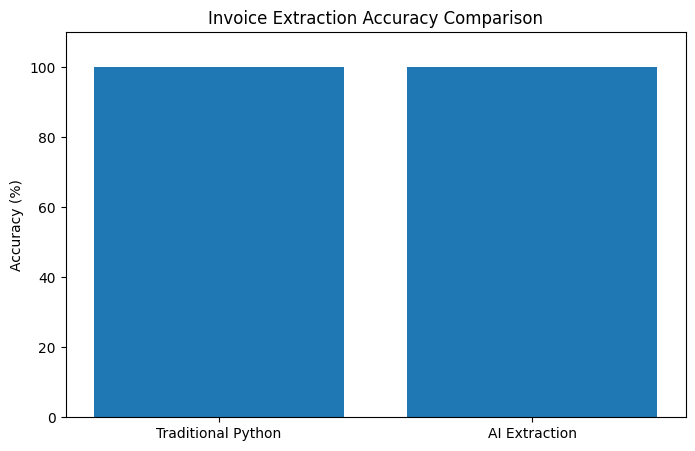

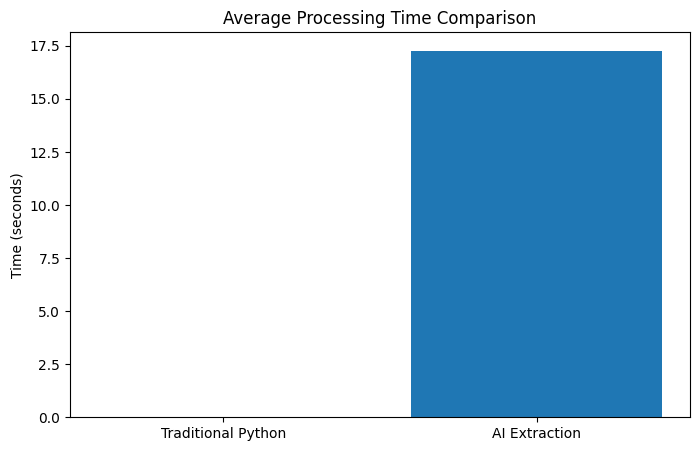

In [45]:

import matplotlib.pyplot as plt

# 1. Compare extraction accuracy
plt.figure(figsize=(8, 5))

plt.bar(
    summary["Method"],
    summary["Accuracy (%)"]
)

plt.title("Invoice Extraction Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)
plt.show()


# 2. Compare processing time
plt.figure(figsize=(8, 5))

plt.bar(
    ["Traditional Python", "AI Extraction"],
    [traditional_avg, ai_avg]
)

plt.title("Average Processing Time Comparison")
plt.ylabel("Time (seconds)")
plt.show()


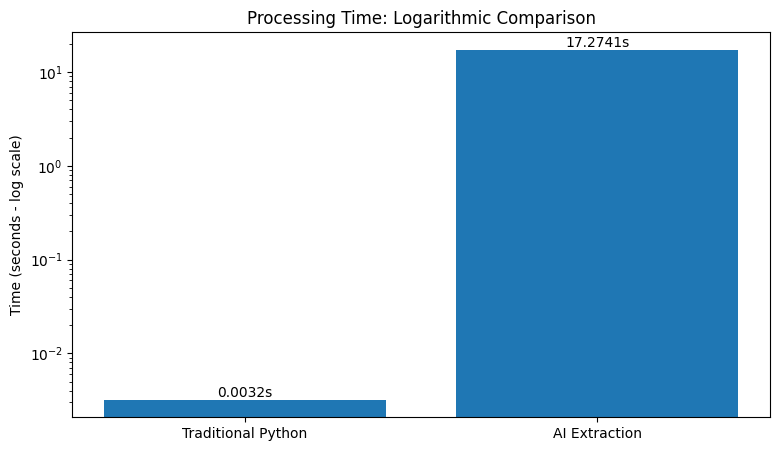

In [46]:

plt.figure(figsize=(9, 5))

methods = ["Traditional Python", "AI Extraction"]
times = [traditional_avg, ai_avg]

bars = plt.bar(methods, times)

plt.yscale("log")

plt.title("Processing Time: Logarithmic Comparison")
plt.ylabel("Time (seconds - log scale)")

for bar, value in zip(bars, times):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f"{value:.4f}s",
        ha="center",
        va="bottom"
    )

plt.show()


## Research Findings – AI vs Traditional Invoice Extraction

### 1. Extraction Accuracy
Both Traditional Python and AI-based extraction achieved 100% accuracy across the five tested invoices.

### 2. Processing Performance
Traditional Python completed extraction significantly faster than AI-based extraction.

- Traditional Python: 0.0032 seconds (average).
- AI extraction: 17.2741 seconds (average).

### 3. Financial Validation
Both extraction methods successfully passed all five financial validations, with no failed validations.

### 4. Key Observation
For these structured synthetic invoices, traditional Python offered superior processing speed while maintaining the same extraction accuracy as AI.

### 5. Research Limitation
The experiment used only five synthetic invoices. Further testing with larger datasets, different invoice layouts, scanned documents and real-world invoices is necessary before drawing broader conclusions.

In [47]:

# Export all project results

traditional_df.to_csv(
    "Traditional_Invoice_Extraction.csv",
    index=False
)

ai_batch_df.to_csv(
    "AI_Invoice_Extraction.csv",
    index=False
)

summary.to_csv(
    "Extraction_Validation_Summary.csv",
    index=False
)

benchmark_df.to_csv(
    "Performance_Benchmark.csv",
    index=False
)

print("All four project files exported successfully!")


All four project files exported successfully!


In [49]:

import os
import glob

# Find all exported CSV files
csv_files = glob.glob("*.csv")

print("Exported CSV files:")
for file in csv_files:
    print(file, "-", round(os.path.getsize(file) / 1024, 2), "KB")

print("\nTotal CSV files found:", len(csv_files))


Exported CSV files:
AI_Invoice_Extraction.csv - 0.51 KB
Performance_Benchmark.csv - 0.1 KB
AI_Extracted_Invoices.csv - 0.51 KB
Extraction_Validation_Summary.csv - 0.16 KB
Traditional_Invoice_Extraction.csv - 0.76 KB

Total CSV files found: 5


In [50]:

import pandas as pd
import glob

for file in glob.glob("*.csv"):

    df = pd.read_csv(file)

    print("\nFile:", file)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print("-" * 60)



File: AI_Invoice_Extraction.csv
Shape: (5, 7)
Columns: ['Invoice_ID', 'Invoice_Date', 'Customer', 'Product', 'Quantity', 'Unit_Price', 'Total_Amount']
------------------------------------------------------------

File: Performance_Benchmark.csv
Shape: (2, 2)
Columns: ['Method', 'Average Time (seconds)']
------------------------------------------------------------

File: AI_Extracted_Invoices.csv
Shape: (5, 7)
Columns: ['Invoice_ID', 'Invoice_Date', 'Customer', 'Product', 'Quantity', 'Unit_Price', 'Total_Amount']
------------------------------------------------------------

File: Extraction_Validation_Summary.csv
Shape: (2, 6)
Columns: ['Method', 'Total Invoices', 'Successful Validations', 'Failed Validations', 'Total Revenue', 'Accuracy (%)']
------------------------------------------------------------

File: Traditional_Invoice_Extraction.csv
Shape: (5, 12)
Columns: ['Invoice_ID', 'Invoice_Date', 'Customer', 'Product', 'Quantity', 'Unit_Price', 'Total_Amount', 'Calculated_Amount', 'A

In [51]:

import pandas as pd

ai_file_1 = pd.read_csv("AI_Invoice_Extraction.csv")
ai_file_2 = pd.read_csv("AI_Extracted_Invoices.csv")

print("Are both AI datasets identical?")
print(ai_file_1.equals(ai_file_2))

print("\nAI dataset preview:")
display(ai_file_1.head())

print("\nTraditional dataset preview:")
display(traditional_df.head())


Are both AI datasets identical?
True

AI dataset preview:


,Invoice_ID,Invoice_Date,Customer,Product,Quantity,Unit_Price,Total_Amount
0,INV-2026-001,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,7080.0
1,INV-2026-002,12 November 2026,Zenith Retail Group,Wireless barcode scanners,4,5500.0,25960.0
2,INV-2026-003,14 November 2026,PQR Food Traders,Recyclable shipping boxes,120,45.0,6372.0
3,INV-2026-004,16 November 2026,Cedar Consulting,Ergonomic office chairs,3,8250.0,29205.0
4,INV-2026-005,18 November 2026,Riverbend Training Centre,Whiteboard marker sets,15,280.0,4956.0



Traditional dataset preview:


,Invoice_ID,Invoice_Date,Customer,Product,Quantity,Unit_Price,Total_Amount,Calculated_Amount,Amount_Match,Calculated_Subtotal,Calculated_GST,Expected_Total
0,INV-2026-001,10 November 2026,ABC Learning Services,Office notebooks,50,120.0,7080.0,6000.0,True,6000.0,1080.0,7080.0
1,INV-2026-002,12 November 2026,Zenith Retail Group,Wireless barcode scanners,4,5500.0,25960.0,22000.0,True,22000.0,3960.0,25960.0
2,INV-2026-003,14 November 2026,PQR Food Traders,Recyclable shipping boxes,120,45.0,6372.0,5400.0,True,5400.0,972.0,6372.0
3,INV-2026-004,16 November 2026,Cedar Consulting,Ergonomic office chairs,3,8250.0,29205.0,24750.0,True,24750.0,4455.0,29205.0
4,INV-2026-005,18 November 2026,Riverbend Training Centre,Whiteboard marker sets,15,280.0,4956.0,4200.0,True,4200.0,756.0,4956.0


In [52]:

import os

duplicate_file = "AI_Extracted_Invoices.csv"

if os.path.exists(duplicate_file):
    os.remove(duplicate_file)
    print("Duplicate file removed successfully!")
else:
    print("Duplicate file not found.")

print("\nRemaining CSV files:")
for file in glob.glob("*.csv"):
    print(file)


Duplicate file removed successfully!

Remaining CSV files:
AI_Invoice_Extraction.csv
Performance_Benchmark.csv
Extraction_Validation_Summary.csv
Traditional_Invoice_Extraction.csv


In [53]:

import os
import shutil

# Create project directory
project_folder = "AI_Invoice_Extraction_Project"

os.makedirs(project_folder, exist_ok=True)

# Move CSV files into the project folder
for file in glob.glob("*.csv"):
    shutil.move(
        file,
        os.path.join(project_folder, file)
    )

print("Project folder created successfully!")

print("\nProject files:")
for file in os.listdir(project_folder):
    print(file)


Project folder created successfully!

Project files:
AI_Invoice_Extraction.csv
Performance_Benchmark.csv
Extraction_Validation_Summary.csv
Traditional_Invoice_Extraction.csv
